In [2]:
import pltkit
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, ScalarFormatter, FormatStrFormatter
import xarray as xr
from scipy.stats import qmc
from scipy.special import erfinv
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba
import sys, os, glob, re, prism, cartopy, pyreadr
from adjustText import adjust_text
sys.path.append(os.path.abspath(".."))
import models.Carleton2022.model.mortality_functions as mf
import models.Burkart2022.model.PAF_calculations as bpaf

In [3]:
"""
PARAMS
"""
wdir = "X:/user/liprandicn/projects/mt-comparison/"

labelsize=13
titlesize=14
lettersize=12
legendsize=12
sub_titlesize=10
sub_labelsize=8

### Burkart 2021

In [ ]:
"""
TEMPERATURE ZONES
"""

# Open precalculated temperature zones netcdf file
era5_tz = xr.open_dataset(wdir + "models/burkart2022/data/TemperatureZones/ERA5_mean_1980-2019_land_t2m_tz.nc")

fig = plt.figure(figsize=(12,6), dpi=450)
ax = fig.add_subplot(111, projection=cartopy.crs.Robinson(central_longitude=0), frameon=True)
ax.set_rasterization_zorder(3)
ax.coastlines(resolution='50m', lw = 0.1)
ax.add_feature(cartopy.feature.OCEAN, facecolor='white', zorder=2)
ax.spines['geo'].set_linewidth(0.2)

# Plot the temperature zones
im = era5_tz.t2m.plot(
    ax=ax,
    transform=cartopy.crs.PlateCarree(),
    infer_intervals=False,
    cbar_kwargs = {
        "orientation": "horizontal", 
        "shrink":0.5, 
        "pad":0.06, 
        "aspect":20, 
        "label":"Temperature zones", 
        "ticks": [6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28]
        },
    vmin=6,
    vmax=28, 
    levels=23,
    extend="both",
    cmap = "cividis"
    )

# Change colour Antarctica 
land_shp = cartopy.io.shapereader.natural_earth(resolution='110m', category='physical', name='land')
land_geoms = cartopy.io.shapereader.Reader(land_shp).geometries()
for land in land_geoms:
    if land.bounds[1] < -60:
        ax.add_geometries([land], cartopy.crs.PlateCarree(), 
                          facecolor='whitesmoke', 
                          edgecolor='none', 
                          zorder=2)

# Save
plt.rcParams['pdf.compression'] = True
plt.savefig(wdir +"/figures/Paper1/Appendix/SM_Burkart_TemperatureZones.pdf", dpi=450, bbox_inches='tight')
plt.show()

In [ ]:
"""
BURKART ERFs
"""

sets = bpaf.ModelSettings(
        wdir=wdir+"models/burkart2022/",
        temp_dir="X:/user/liprandicn/Data/ERA5/t2m_daily",
        project=None,
        scenario="SSP2_ERA5",
        years=[2010],
        draw="mean",
        single_erf=False, 
        extrap_erf=False,
    )

# Load ERFs
erf = bpaf.LoadExposureResponseFunctionsAll(sets)

for cause in pltkit.causes.keys():
    erf[cause] = erf[cause].set_index("temperature_zone")
    erf[cause]["mean"] = erf[cause].iloc[:,1:].mean(axis=1)

plt.rcParams["axes.prop_cycle"] = plt.cycler("color", plt.cm.cividis(np.linspace(0,1,23)))

fig, axs = plt.subplots(5,4, figsize=(12,14))
axs = axs.flatten()

for i, cause in enumerate(pltkit.causes.keys()):
    
    for tz in range(6,29):
        
        x = erf[cause]["daily_temperature"].loc[tz].values   # Daily Temperature
        y = erf[cause]["mean"].loc[tz].values    # Relative Risk        
        axs[i].plot(x, y, label=tz)
        
    axs[i].axhline(y=0.99, color="grey", linestyle="--", zorder=1)
    axs[i].tick_params(axis='both', length=0)

    pltkit.StylizeAxes(
        axs[i],
        facecolor="whitesmoke",
        grid=True, 
        grid_kwargs={"c":"white"}, 
        title=f"{pltkit.causes[cause]}", 
        title_kwargs={"fontsize":sub_titlesize, "fontweight":"bold", "y":1.02}, 
        spines={"top":False, "right":False, "left":False, "bottom":False},
        ylim=(0.75,2)
        )
    
    for i in [0, 4, 8, 12, 16]:
        pltkit.StylizeAxes(
            axs[i],
            ylabel="Relative Risk (RR)",
            ylabel_kwargs={"fontsize":sub_labelsize}
            )
    for i in range(13,17):
        pltkit.StylizeAxes(
            axs[i],
            xlabel="Daily mean temperature (°C)",
            xlabel_kwargs={"fontsize":sub_labelsize}
            )

for i in [17, 18, 19]:
    axs[i].axis('off')

plt.tight_layout()
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.65, 0.15), ncol=8, title="Temperature zones", title_fontsize=legendsize)

plt.savefig(wdir +"/figures/Paper1/Appendix/SM_Burkart_ERFs.pdf", dpi=450, bbox_inches='tight')

In [ ]:
"""
RESULTS TABLE APPENDIX
"""

filename = "mortality_ReplicationBurkart_SSP2_ERA5_1990-2019_*"
region_type="IMAGE"
region = "World"
t_type = "all"
cause = "All causes"
age_group = "All ages"
variable = "mortality"

bur_mean, bur_p025, bur_p975 = pltkit.LoadMortalityDraws(wdir+"burkart2022/output/ReplicationBurkart", filename, region_type, region, t_type, cause, age_group, variable)
print(f"Mean: 1990: {bur_mean.sel(year=1990).values}, 2000: {bur_mean.sel(year=2000).values}, 2010: {bur_mean.sel(year=2010).values}, 2019: {bur_mean.sel(year=2019).values}")
print(f"P2.5: 1990: {bur_p025.sel(year=1990).values}, 2000: {bur_p025.sel(year=2000).values}, 2010: {bur_p025.sel(year=2010).values}, 2019: {bur_p025.sel(year=2019).values}")
print(f"P97.5: 1990: {bur_p975.sel(year=1990).values}, 2000: {bur_p975.sel(year=2000).values}, 2010: {bur_p975.sel(year=2010).values}, 2019: {bur_p975.sel(year=2019).values}")


colors = ["#8C9A9E", "#6F1A07", "#5B9279", "#022B3A", "#E3B448"]
fig, ax = plt.subplots(figsize=(6,5))

plt.plot(bur_mean.year, bur_mean, label="Burkart et al., 2021", linewidth=2, c=colors[0])
plt.fill_between(bur_mean.year, bur_p025, bur_p975, color=colors[0], alpha=0.3)


plt.title(f"{region} {variable} estimations | {t_type.capitalize()} | {age_group.capitalize()} age group")
plt.legend(frameon=False)
plt.ylabel("Excess mortality (thousand people)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Carleton 2022

In [ ]:
"""
IMPACT REGIONS
"""
ir = gpd.read_file(wdir + "models/carleton2022/data/CarletonSM/ir_shp/impact-region.shp")

fig = plt.figure(figsize=(12,6), dpi=450)
ax = fig.add_subplot(111, projection=cartopy.crs.Robinson(central_longitude=0), frameon=True)
ax.set_rasterization_zorder(3)

ax.coastlines(resolution='10m', lw = 0.1)
gl = ax.gridlines(crs=cartopy.crs.PlateCarree(), draw_labels=False, linewidth=0, color='white', alpha=0.5)
ax.spines['geo'].set_linewidth(0.2)

im = ir.boundary.plot(
    ax=ax,
    transform=cartopy.crs.PlateCarree(),
    color="black",
    linewidth=0.05
    )
ax.add_feature(cartopy.feature.OCEAN, facecolor='white', zorder=2)

plt.savefig(wdir + "figures/Paper1/Appendix/SM_Carleton_ir.pdf", dpi=450, bbox_inches='tight')
plt.show()

In [ ]:
"""
Carleton ERFs
"""

# Load ERFs
flattened_config = {}
flattened_config["wdir"] = wdir+"models/carleton2022"
flattened_config["temp_dir"] = "X:/user/liprandicn/Data/ERA5/t2m_daily"
flattened_config["gdp_dir"] = None
flattened_config["project"] = "default"
flattened_config["scenario"] = "SSP2_L"
flattened_config["start_year"] = 1980
flattened_config["end_year"] = 2015
flattened_config["adaptation"] = None
flattened_config["counterfactual"] = None
flattened_config["reporting_tool"] = None
flattened_config["draw"] = "mean"
flattened_config["monthly_output"] = False
flattened_config["impact_regions"] = False
flattened_config["dask_on"] = False
flattened_config["stochastic"] = False

sets = mf.ModelSettings(**flattened_config)
base = mf.LoadInputData.for_baseline(sets=sets)
gamma_coeffs = mf.ImportGammaCoefficients(sets, sets.draw)

erfs_t0, tmin_t0 = mf.GenerateERFAll(
    sets=sets, 
    base=base,
    tempe=None,
    scen=None,
    erf=None,
    gammas=gamma_coeffs,
    year=None, 
    adaptation=False, 
    counterfactual=None
    ) 

fig, axs = plt.subplots(1,3, figsize=(12,4), dpi=450)
axs = axs.flatten()
t = np.arange(-20, 40.1, 0.1).round(1)
age_groups = ["+65 years", "5-64 years", "0-4 years"]

for i, age in enumerate(["oldest", "older", "young"]):
    
    axs[i].set_rasterization_zorder(3)
    axs[i].plot(t, erfs_t0[:,i].mean(axis=0), color="k", linewidth=2, zorder=3)
    for j in range(24378):
        axs[i].plot(t, erfs_t0[j,i], color="silver", alpha=0.1, linewidth=0.1, zorder=2)
    pltkit.StylizeAxes(
        axs[i], 
        facecolor="white",
        title=age_groups[i],
        title_kwargs={"fontsize": titlesize, "fontweight": "bold"},
        xlabel="Daily temperature (°C)",
        ylim=(0, 16),
        xlim=(-20, 40),
        spines={"top":False, "right":False}
    )
axs[0].set_ylabel("Relative mortality \n (deaths per 100,000 people)", fontsize=labelsize)
plt.tight_layout()

plt.savefig(wdir+"/figures/Paper1/Appendix/SM_Carleton_ERFs.pdf", dpi=450, bbox_inches='tight')
plt.show()

In [ ]:
"""
Replication Figure
"""

mor_2050 = pd.read_csv(wdir+'models/carleton2022/data/CarletonSM/erf_replication/TMEANt_logGDPt_oldest_2050.csv', index_col=[0])
mor_2100 = pd.read_csv(wdir+'models/carleton2022/data/CarletonSM/erf_replication/TMEANt_logGDPt_oldest_2100.csv', index_col=[0])
oldest = pd.read_csv(wdir+'models/carleton2022/data/CarletonSM/erf_replication/oldest.csv', index_col=[1])

delta_2050 = mor_2050['35.0'] - oldest['35.0']
delta_2100 = mor_2100['35.0'] - oldest['35.0']

ir = gpd.read_file(wdir+"models/carleton2022/data/CarletonSM/ir_shp/impact-region.shp")

ir['delta_2050'] = delta_2050.values
ir['delta_2100'] = delta_2100.values

ir = ir[~ir["hierid"].str.contains("ATA")]

fig, ax = plt.subplots(1, 2, figsize=(12, 6), dpi=450, subplot_kw={'projection': cartopy.crs.Robinson()})

vmin, vmax = -21, 2
cmap = 'YlGn_r'

ir.plot(column='delta_2050', ax=ax[0], legend=False, cmap=cmap, vmin=vmin, vmax=vmax, rasterized=True, transform=cartopy.crs.PlateCarree())
ax[0].set_title('2050', fontsize=titlesize)
ax[0].axis('off')

ir.plot(column='delta_2100', ax=ax[1], legend=False, cmap=cmap, vmin=vmin, vmax=vmax, rasterized=True, transform=cartopy.crs.PlateCarree())
ax[1].set_title('2100', fontsize=titlesize)
ax[1].axis('off')

plt.subplots_adjust(wspace=0.01, bottom=0.25) 

cax = fig.add_axes([0.4, 0.3, 0.3, 0.03]) 
cbar = fig.colorbar(ax[1].collections[0], cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=labelsize, size=3, width=0.5)

cbar.set_label('Change in relative mortality\n(deaths per 100,000 people)', fontsize=legendsize)
plt.savefig(wdir+"/figures/Paper1/Appendix/SM_Carleton_Replication.pdf", dpi=450, bbox_inches='tight')
plt.show()

### Honda 2014

In [ ]:
"""
Honda ERF
"""

df_interp = pd.read_csv(wdir + "models/Honda2014/data/risk_function/RiskFunction_Honda.csv")

fig, ax = plt.subplots(figsize=(6,5), dpi=450)
ax.plot(df_interp["daily_temperature"], df_interp["relative_risk_mean"], color="k")
ax.fill_between(
    df_interp["daily_temperature"], 
    df_interp["relative_risk_lower"], 
    df_interp["relative_risk_upper"], 
    alpha=0.2, color="k")
pltkit.StylizeAxes(
    ax=ax,
    spines={"top":False, "right":False},
    xlabel="Daily temperature (°C) - OT",
    ylabel="Relative Risk",
    title="Risk function of excess mortality due to heat",
    title_kwargs={"fontsize": labelsize, "y":1.05},
)

plt.tight_layout()
plt.savefig(wdir+"/figures/Paper1/Appendix/SM_Honda_ERF.pdf", dpi=450, bbox_inches='tight')

In [ ]:
"""
Optimal temperatures map
"""

ot = xr.open_dataset(wdir+"models/honda2014/data/optimal_temperatures/era5_t2m_max_1980-2010_p84.nc")

fig = plt.figure(figsize=(12,6), dpi=450)
ax = fig.add_subplot(111, projection=cartopy.crs.Robinson(central_longitude=0), frameon=True)
ax.set_rasterization_zorder(3)
ax.coastlines(resolution='10m', lw = 0.1)
gl = ax.gridlines(crs=cartopy.crs.PlateCarree(), draw_labels=False, linewidth=0, color='white', alpha=0.5)
ax.spines['geo'].set_linewidth(0.2)

im = ot.t2m_p84.plot(ax=ax, 
                transform=cartopy.crs.PlateCarree(), 
                cmap='RdBu_r', 
                add_colorbar=False,
                levels=21, 
                vmin=-40, 
                vmax=40)
ax.add_feature(cartopy.feature.OCEAN, facecolor='white', zorder=2)

# Manually set colorbar limits
cbar = fig.colorbar(im, ax=ax, orientation='vertical', shrink=0.6, pad=0.05, aspect=20)
cbar.ax.set_ylim(-12, 36) 
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%d°C'))

# Remove Antarctica 
land_shp = cartopy.io.shapereader.natural_earth(resolution='110m', category='physical', name='land')
land_geoms = cartopy.io.shapereader.Reader(land_shp).geometries()
for land in land_geoms:
    if land.bounds[1] < -60:
        ax.add_geometries([land], cartopy.crs.PlateCarree(), 
                          facecolor='whitesmoke', 
                          edgecolor='none', 
                          zorder=2)
        
plt.title('Optimal daily maximum temperatures (OT)', fontsize=10)
plt.savefig(wdir+"figures/Paper1/Appendix/SM_Honda_Map.pdf", dpi=450, bbox_inches='tight')
plt.show()

In [ ]:
"""
Replication Romanello 2024
"""

filename = "models/honda2014/output/ReplicationRomanello/mortality_ReplicationRomanello_SSP2_ERA5_2000-2023"

rt = "IMAGE"
temp_type = "heat"
age_group = "oldest"
region = "World"
cause = "All causes"
var = "mortality"

rom = pltkit.LoadMortality(wdir, filename, rt, region, temp_type, cause, age_group, var)

fig = plt.figure(figsize=(10,5), dpi=450)
plt.plot(rom.year, rom.sel(var_mor="mean"), label="Romanello et al., 2024", linewidth=2, c="k")
plt.fill_between(rom.year, rom.sel(var_mor="lower"), rom.sel(var_mor="upper"), alpha=0.2, color="k")

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((5, 5))
plt.gca().yaxis.set_major_formatter(formatter)
plt.grid(False)
plt.ylim(0, 5e5)
plt.title("Heat-related mortality", fontsize=titlesize)
plt.ylabel("Excess mortality over 65", fontsize=labelsize)

plt.savefig(wdir + "figures/Paper1/Appendix/SM_Honda_Replication.pdf", dpi=450, bbox_inches='tight')
plt.show()

### Scovronick 2024

In [ ]:
"""
Scoronick ERFs
"""

result = pyreadr.read_r(wdir + "models/scovronick2024/data/Scovronick_SM/Fig2_20Nov2025.RData")

fig, axs = plt.subplots(2, 2, figsize=(12,8), dpi=450)
axs = axs.flatten()

groups = ['40', '55', '70', '85']
diseases = ['ncrc', 'rsp', 'cvd', 'all']
cause_name = ['Non-cardiorespiratory diseases', 'Respiratory diseases', 'Cardiovascular diseases', 'All-cause mortality']

colors = plt.cm.tab10(range(len(groups))) 

for i, disease in enumerate(diseases):
    for j, group in enumerate(groups):
        color = colors[j]

        x = result[disease]['Percentile']
        y = result[disease][f'{disease}_{group}_rr']
        low = result[disease][f'{disease}_{group}_rr_low']
        high = result[disease][f'{disease}_{group}_rr_high']

        # Central line
        axs[i].plot(x, y, label=f'Age {group}', color=color, zorder=2)
        # Uncertainty range
        axs[i].fill_between(x, low, high, color=color, alpha=0.25, zorder=2)

    pltkit.StylizeAxes(
        axs[i], 
        title=cause_name[i],
        title_kwargs={"fontsize": titlesize, "fontweight": "bold", "y":1.02},
        ylim=(0.9, 1.65),
        spines={'top': False, 'right': False},
        grid=True, 
        grid_kwargs={"c":"white"},
        )

    if i == 0 or i == 2:
        axs[i].set_ylabel('Relative Risk (RR)', fontsize=labelsize)
    if i == 2 or i == 3:
        axs[i].set_xlabel('Percentile of Temperature', fontsize=labelsize)

    axs[i].axhline(1.0, linestyle='--', color='silver')

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=8, title="Age", title_fontsize=titlesize)

plt.tight_layout()
plt.savefig(wdir + "/figures/Paper1/Appendix/SM_Scovronick_ERFs.pdf", dpi=450, bbox_inches='tight')
plt.show()

### Comparison

In [ ]:
"""
Params
"""

temp_type = "heat"
age_group = "oldest"
cause = "All causes"
rt = "IMAGE"
var = "mortality"

models = {
    "hon_file" : [
        0,
        "honda2014/output/ComparisonHonda/mortality_ComparisonHonda_SSP2_ERA5_1980-2023_counterfactual",
        "Honda et al., 2014",
        "H"
        ],
    "sco_file" : [
        1,
        "scovronick2024/output/ComparisonScovronick/mortality_ComparisonScovronick_SSP2_ERA5_1980-2023_counterfactual",
        "Scovronick et al., 2024",
        "S"
        ],
    "car_file" : [
        2,
        "carleton2022/output/ComparisonCarletonCounter/mortality_ComparisonCarletonCounter_SSP2_ERA5_NoAdap_1980-2023_*",
        "Carleton et al., 2022",
        "C"
        ],       
    "bur_file" : [
        3,
        "burkart2022/output/ComparisonBurkart/mortality_ComparisonBurkart_SSP2_ERA5_1980-2023_counterfactual_*",
        "Burkart et al., 2021",
        "B"
        ]
    }

In [ ]:
df = pd.read_csv(wdir+"figures/Paper1/Appendix_HistoricalMortality_Continents.csv")

continents= {
    "Northern America": ["CAN", "USA"],
    "Europe": ["WEU", "CEU", "UKR"],
    "Asia": ["TUR", "STAN", "RUS", "ME", "INDIA", "KOR", "CHN", "SEAS", "INDO", "JAP", "RSAS"],
    "Latin America and the Caribbean": ["MEX", "RCAM", "BRA", "RSAM"],
    "Africa": ["NAF", "WAF", "EAF", "SAF", "RSAF"],
    "Oceania": ["OCE"]
    }

region_to_continent = {
    region: continent 
    for continent, regions in continents.items() 
    for region in regions
}
df['Continent'] = df['Region'].map(region_to_continent)
df = df.groupby(['Continent', 'File', 'Type']).sum(numeric_only=True).reset_index()
continents.keys()

fig, axs = plt.subplots(2,3, figsize=(12,8), dpi=450)
axs = axs.flatten()

colors_list = ["#C8553D", "#566E3D", "#222E50", "#FEA82F", "#829191"]

years_vlines = [1998, 2003, 2010, 2016, 2019, 2022]

for i,region in enumerate(list(continents.keys())):
    for j, model in enumerate(models):
        main = df[(df['Continent'] == region) & (df['File'] == model) & (df["Type"]=="main")].iloc[:,3:]
        lower = df[(df['Continent'] == region) & (df['File'] == model) & (df["Type"]=="lower")].iloc[:,3:]
        upper = df[(df['Continent'] == region) & (df['File'] == model) & (df["Type"]=="upper")].iloc[:,3:]
        
        axs[i].plot(main.columns.astype(int), main.values[0], label=models[model][2], linewidth=2, c=colors_list[j], clip_on=False)
        fill = axs[i].fill_between(main.columns.astype(int), lower.values[0], upper.values[0], color=colors_list[j], alpha=0.3)
        fill.set_clip_on(False)

    # for year in years_vlines:
    #     axs[i].axvline(x=year, color='gray', linestyle='--', linewidth=1, alpha=0.7)
        
    axs[i].set_title(f"{region}", fontsize=titlesize, y=1.1)
    axs[i].tick_params(axis='both', labelsize=labelsize)
    axs[i].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1000:g}k'))
    axs[i].spines["top"].set_visible(False)
    axs[i].spines["right"].set_visible(False)
    
    if (i==0) or (i==3):
        axs[i].set_ylabel("Global excess mortality", fontsize=labelsize)
        
axs[0].set_ylim(-10e3,25e3)
axs[1].set_ylim(-2e3,100e3)
axs[4].set_ylim(-10e3,105e3)
axs[3].set_ylim(-10e3,96e3)
axs[2].set_ylim(-100e3,500e3)
axs[5].set_ylim(-0.5e3,2.1e3)


handles, labels = axs[0].get_legend_handles_labels()
fig.legend(
    handles=handles,
    labels=labels,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.0),
    ncol=len(models),
    frameon=False,
    fontsize=labelsize
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(wdir+"figures/Paper1/Appendix/SM_Comparison_Continents.pdf", dpi=450, bbox_inches='tight')
plt.show()

In [ ]:
# Load regional values for insets
# Run only once

# region_vals={}
# for region in pltkit.IMAGE_REGIONS:
#     region_vals[region] = {"main": {}, "lower": {}, "upper": {}}
#     for i,model in enumerate(models):
#         m, l, u = pltkit.LoadMortalityDraws(wdir+"models/", models[model][1], rt, region, temp_type, cause, age_group, var, None)
#         region_vals[region]["main"][model] = m.values
#         region_vals[region]["lower"][model] = l.values
#         region_vals[region]["upper"][model] = u.values
        
# years=range(1980,2024)

# rows = []
# for region, sub_dict in region_vals.items():
#     for main_key, files_dict in sub_dict.items():
#         for file_name, array_data in files_dict.items():
#             for val, year in zip(array_data, years):
#                 rows.append({
#                     'Region': region,
#                     'Type': main_key,
#                     'File': file_name,
#                     'Value': val,
#                     "Year":year
#                 })

# df = pd.DataFrame(rows)

# df = df.pivot_table(
#     index=['Region', 'File', "Type"], 
#     columns='Year', 
#     values='Value'
# ).reset_index()

# df.to_csv(wdir+"figures/Paper1/Appendix_HistoricalMortality_Continents.csv", index=False)

In [ ]:
### ------------- Add lower figures (Separated vertically) -------------
df_anual = pd.read_csv(wdir+"figures\\Paper1\\figure1_people_days_heat.csv", index_col=0)

fig = plt.figure(figsize=(12,6), dpi=450)

temperatures = [25, 30, 35]
colors_reds = ["#FFC2C2", "#FF6B6B", "#C90000"]
years_vlines = [1998, 2010, 2016, 2019, 2022]
explicit_xticks = [1980, 1990, 2000, 2010, 2020]

# Parameters
x_start = 0
y_start = 0
width = 1
total_height = 1

num_plots = len(temperatures)
gap = 0.05 # Vetrical gap between subplots (in figure coordinates)
sub_height = (total_height - (gap * (num_plots - 1))) / num_plots

for i, t in enumerate(temperatures):
    # Get y position for the current subplot
    y_pos = y_start + (num_plots - 1 - i) * (sub_height + gap)
    
    # Create new axis
    ax_sub = fig.add_axes([x_start, y_pos, width, sub_height])
    
    # Plot data
    y_data = df_anual[f"{t}"] / df_anual["GPOP"]
    ax_sub.plot(df_anual.index, y_data, label=f"{t}°C", c=colors_reds[i], linewidth=4)
    
    for year in years_vlines:
        ax_sub.axvline(x=year, color='gray', linestyle='--', linewidth=2, alpha=0.7)
    
    # Configure axis
    ax_sub.spines["top"].set_visible(False)
    ax_sub.spines["right"].set_visible(False)
    ax_sub.tick_params(axis='both', labelsize=labelsize)
    ax_sub.set_ylabel(f"Days over {t}°C", fontsize=labelsize)
    ax_sub.set_xlim(1979, 2024)
    ax_sub.set_xticks(explicit_xticks)
    
    # Add title only to the first subplot
    if i == 0:
        ax_sub.set_title("Global averaged number of days an individual is exposed to mean temperatures over a certain threshold", fontsize=titlesize, y=1.15)
        
    # Remove x-tick labels for all but the last subplot
    if i < num_plots - 1:
        ax_sub.tick_params(labelbottom=False, bottom=True)
        
plt.savefig(wdir+"figures/Paper1/Appendix/SM_DaysOverT.pdf", bbox_inches='tight')

### Future projections

In [ ]:
"""
ScenarioMIP7 temperature projections
"""

smip_temperature  = {}
smip_temperature_magicc = {}
smip_path = "X:/user/doelmanj/ScenDevelopment/ScenarioMIP/3_IMAGE_land/scen/"

timeline = prism.Timeline(
                start=prism.Q_(1970,"year"), # Can be changed
                end=prism.Q_(2100,"year"),
                stepsize=prism.Q_(1, "year")
                )
SCENARIOS = [
    "SSP1_M_CP", "SSP1_M", "SSP1_ML", "SSP1_L", "SSP1_VLLO", "SSP1_VLHO", 
    "SSP2_M_CP", "SSP2_M", "SSP2_ML", "SSP2_L", "SSP2_VLLO", "SSP2_VLHO",
    "SSP3_M_CP", "SSP3_H",
    "SSP5_H", "SSP5_HL"
    ]

for scenario in SCENARIOS:
    
    scenariomip_temperature = smip_path + scenario + "/output/climate_impacts/TEMPERATURE.OUT"
    
    smip_temperature[scenario] = prism.TimeVariable(
        dims = (),
        unit = "K",
        file = scenariomip_temperature,
        timeline = timeline
    )

ssp_styles = {
    "SSP1": "-", "SSP2": "--", "SSP3": "-.", "SSP5": ":"
}

target_colors = {
    "VLLO": "#4A7C80", 
    "VLHO": "#B89648",  

    "L":    "#B56545",  
    "ML":   "#7E5E8F",  
    
    "M":    "#557A42", 
    "M_CP": "#5B6E91",  
    
    "H":    "#AD526B", 
    "HL":   "#6E6E6E" 
}

fig, ax = plt.subplots(figsize=(12,6), dpi=450)
texts = []

for scenario in SCENARIOS:
    
    parts = scenario.split("_", 1)
    ssp = parts[0]
    target = parts[1]
    
    line_style = ssp_styles.get(ssp, "-")
    line_color = target_colors.get(target, "black")
    
    data_slice = smip_temperature[scenario].to_array().sel(time=slice(2020, 2100))
    data_slice.plot(ax=ax, color=line_color, linestyle=line_style, linewidth=3)
    
    x_end = 2100
    y_end = data_slice.sel(time=x_end).values.item()
    
    t = ax.text(x_end+1, y_end, scenario, color=line_color, va="center", fontsize=legendsize, fontweight='bold')
    texts.append(t)

ax.set_xlim(2025, 2109) 
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("ΔGMST compared to 1850-1900 [K]", fontsize=labelsize)
ax.set_xlabel("")

adjust_text(
    texts, 
    only_move={'text': 'y'},     
    force_points=0.0,            
    expand=(1.0, 1.1),            
)

plt.title("Global temperature of ScenarioMIP-CMIP7 scenarios produced by IMAGE", fontsize=titlesize, y=1.05, weight='bold')
plt.savefig(wdir+"figures/Paper1/Appendix/SM_ScenarioMIP7.pdf", dpi=450, bbox_inches='tight')
plt.show()

In [ ]:
model = "ACCESS-CM2"
var_dir = "X:/user/scherrenbm/Data/Internal_Variability_EERIE/"
file_list = sorted(glob.glob(var_dir+f"//internal_variability_grid_tas_Amon_{model}_hist*.nc"))


fig, ax = plt.subplots(3,3, figsize=(12,15), dpi=450)
ax=ax.flatten()

for i in range(len(file_list)):
    filename = re.search(rf'{model}_hist-(.*?)_gn', file_list[i]).group(1)
    var = xr.open_dataset(file_list[i], decode_times=False).mean(dim="lat").mean(dim="lon").isel(time=slice(-1212, None))
    ax[i].plot(pd.date_range(start='2000-01-01', end='2100-12-31', freq='ME'), var.IV_tas.values, label=filename, c=f"#3d2217", linewidth=0.5)
    ax[i].legend(loc="upper left")
    ax[i].set_ylim(-2,3)
    if i in [0,3,6]:
        ax[i].set_ylabel("ΔT [°C]")
        
plt.suptitle(f"{model}  internal variability", y=0.91, fontsize=titlesize, fontweight="bold")
plt.savefig(wdir+"figures/Paper1/Appendix/SM_Climate_Variability.pdf", dpi=450, bbox_inches='tight')
plt.show()

In [ ]:
with open(wdir+"/models/carleton2022/data/CarletonSM/Agespec_interaction_response.csvv") as f:
    sigma_original = np.zeros((36,36))
    for i, line in enumerate(f, start=1):
        if i == 23:
            gammas = np.array([float(x) for x in line.strip().split(", ")])
        if i in range(25,61):
            sigma_original[i-25] = np.array([float(x) for x in line.strip().split(", ")])


N = sigma_original.shape[0]

# Cholesky decomposition
L = np.linalg.cholesky(sigma_original)

sample_range = range(10, 1000, 10)  
mean_errors = []
iterations_per_size = 50  # Simulations per size to stabilize LHS randomness


# ------------------------- SIMULATION LOOP -------------------------------------------
for M in sample_range:
    iteration_errors = []
    
    for _ in range(iterations_per_size):
        # Initialize Latin Hypercube Sampler
        sampler = qmc.LatinHypercube(d=N)
        uniform_samples = sampler.random(n=M)

        # Inverse transform sampling to standard Normal Distribution N(0,1)
        normal_samples = np.sqrt(2) * erfinv(2 * uniform_samples - 1)

        # Induce the target covariance structure using the Cholesky matrix
        correlated_samples = np.dot(normal_samples, L.T)

        # Compute the empirical covariance matrix from the simulated samples
        sigma_simulated = np.cov(correlated_samples, rowvar=False)

        # Calculate the Frobenius Norm of the matrix difference (relative error metric)
        norma_base = np.linalg.norm(sigma_original, ord='fro')
        frobenius_error = np.linalg.norm(sigma_original - sigma_simulated, ord='fro') / norma_base
        iteration_errors.append(frobenius_error)

    mean_errors.append(np.mean(iteration_errors))

# ------ ELBOW METHOD OPTIMIZATION ---------
relative_changes = np.abs(np.diff(mean_errors) / mean_errors[:-1])
optimal_m = sample_range[-1]  # Default fallback to max samples

for idx, change in enumerate(relative_changes):
    if change < 0.025:  # 2.5% stabilization threshold
        optimal_m = sample_range[idx + 1]
        break

# ---------------------------- CONVERGENCE PLOT -----------------------------------------
fig, ax = plt.subplots(figsize=(10, 6), dpi=450)
plt.plot(sample_range, mean_errors, marker='o', color='darkgrey', linewidth=2, label='Frobenius Norm Error')
plt.axvline(x=100, color='darkolivegreen', linestyle='--', linewidth=2, label=f'100 samples')
plt.title('Covariance Matrix Convergence Curve')
plt.xlabel('Number of Samples')
plt.ylabel('Fit Error Magnitude')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.savefig(wdir+"/figures/Paper1/Appendix/SM_VCMatrix_Convergence.pdf", dpi=450, bbox_inches='tight')
plt.show()

In [ ]:
"""
Mortality model uncertainty shown in 100 draws of the ERF
"""

temp_type = "heat"
unit = "total"
age_group = "All ages"
region = "World"
cause = None
region_type = "IMAGE"
variable = "mortality"

wdir1 = wdir + "models//carleton2022//output//ScenarioMIP7_100draws//"
scenario1_list = sorted(glob.glob(wdir1+"mortality_ScenarioMIP7_100draws_SSP1_L_ssp245_r1_2000-2100_LHScut_100_*_p5-p95.nc"))
scenario2_list = sorted(glob.glob(wdir1+"mortality_ScenarioMIP7_100draws_SSP3_H_ssp245_r1_2000-2100_LHScut_100_*_p5-p95.nc"))

fig, axs = plt.subplots(1,2, figsize=(12,5), dpi=450)
ax = axs.flatten()

for i in range(len(scenario1_list)):
    filename = re.search(r'100draws\\(.*?).nc', scenario1_list[i]).group(1)
    scenario_name = re.search(r'100draws_(.*?)_2000', filename).group(1)
    ds = pltkit.LoadMortality(wdir1, filename, region_type, region, temp_type, cause, age_group, variable)
    ds.plot(ax = ax[0], color="slategray", alpha=0.5, linewidth=0.5)
ax[0].set_title(scenario_name)
ax[0].set_ylabel("Excess mortality [number of people]")
    
for i in range(len(scenario2_list)):
    filename = re.search(r'100draws\\(.*?).nc', scenario2_list[i]).group(1)
    scenario_name = re.search(r'100draws_(.*?)_2000', filename).group(1)
    ds = pltkit.LoadMortality(wdir1, filename, region_type, region, temp_type, cause, age_group, variable)
    ds.plot(ax = ax[1], color="slategray", alpha=0.5, linewidth=0.5)
ax[1].set_title(scenario_name)
ax[1].set_ylabel("")

for i in [0,1]:
    ax[i].spines["top"].set_visible(False)
    ax[i].spines["right"].set_visible(False)
    ax[i].grid(False)
    ax[i].set_xlabel("")

plt.savefig(wdir+"/figures/Paper1/Appendix/SM_LHS100.pdf", dpi=450, bbox_inches='tight')

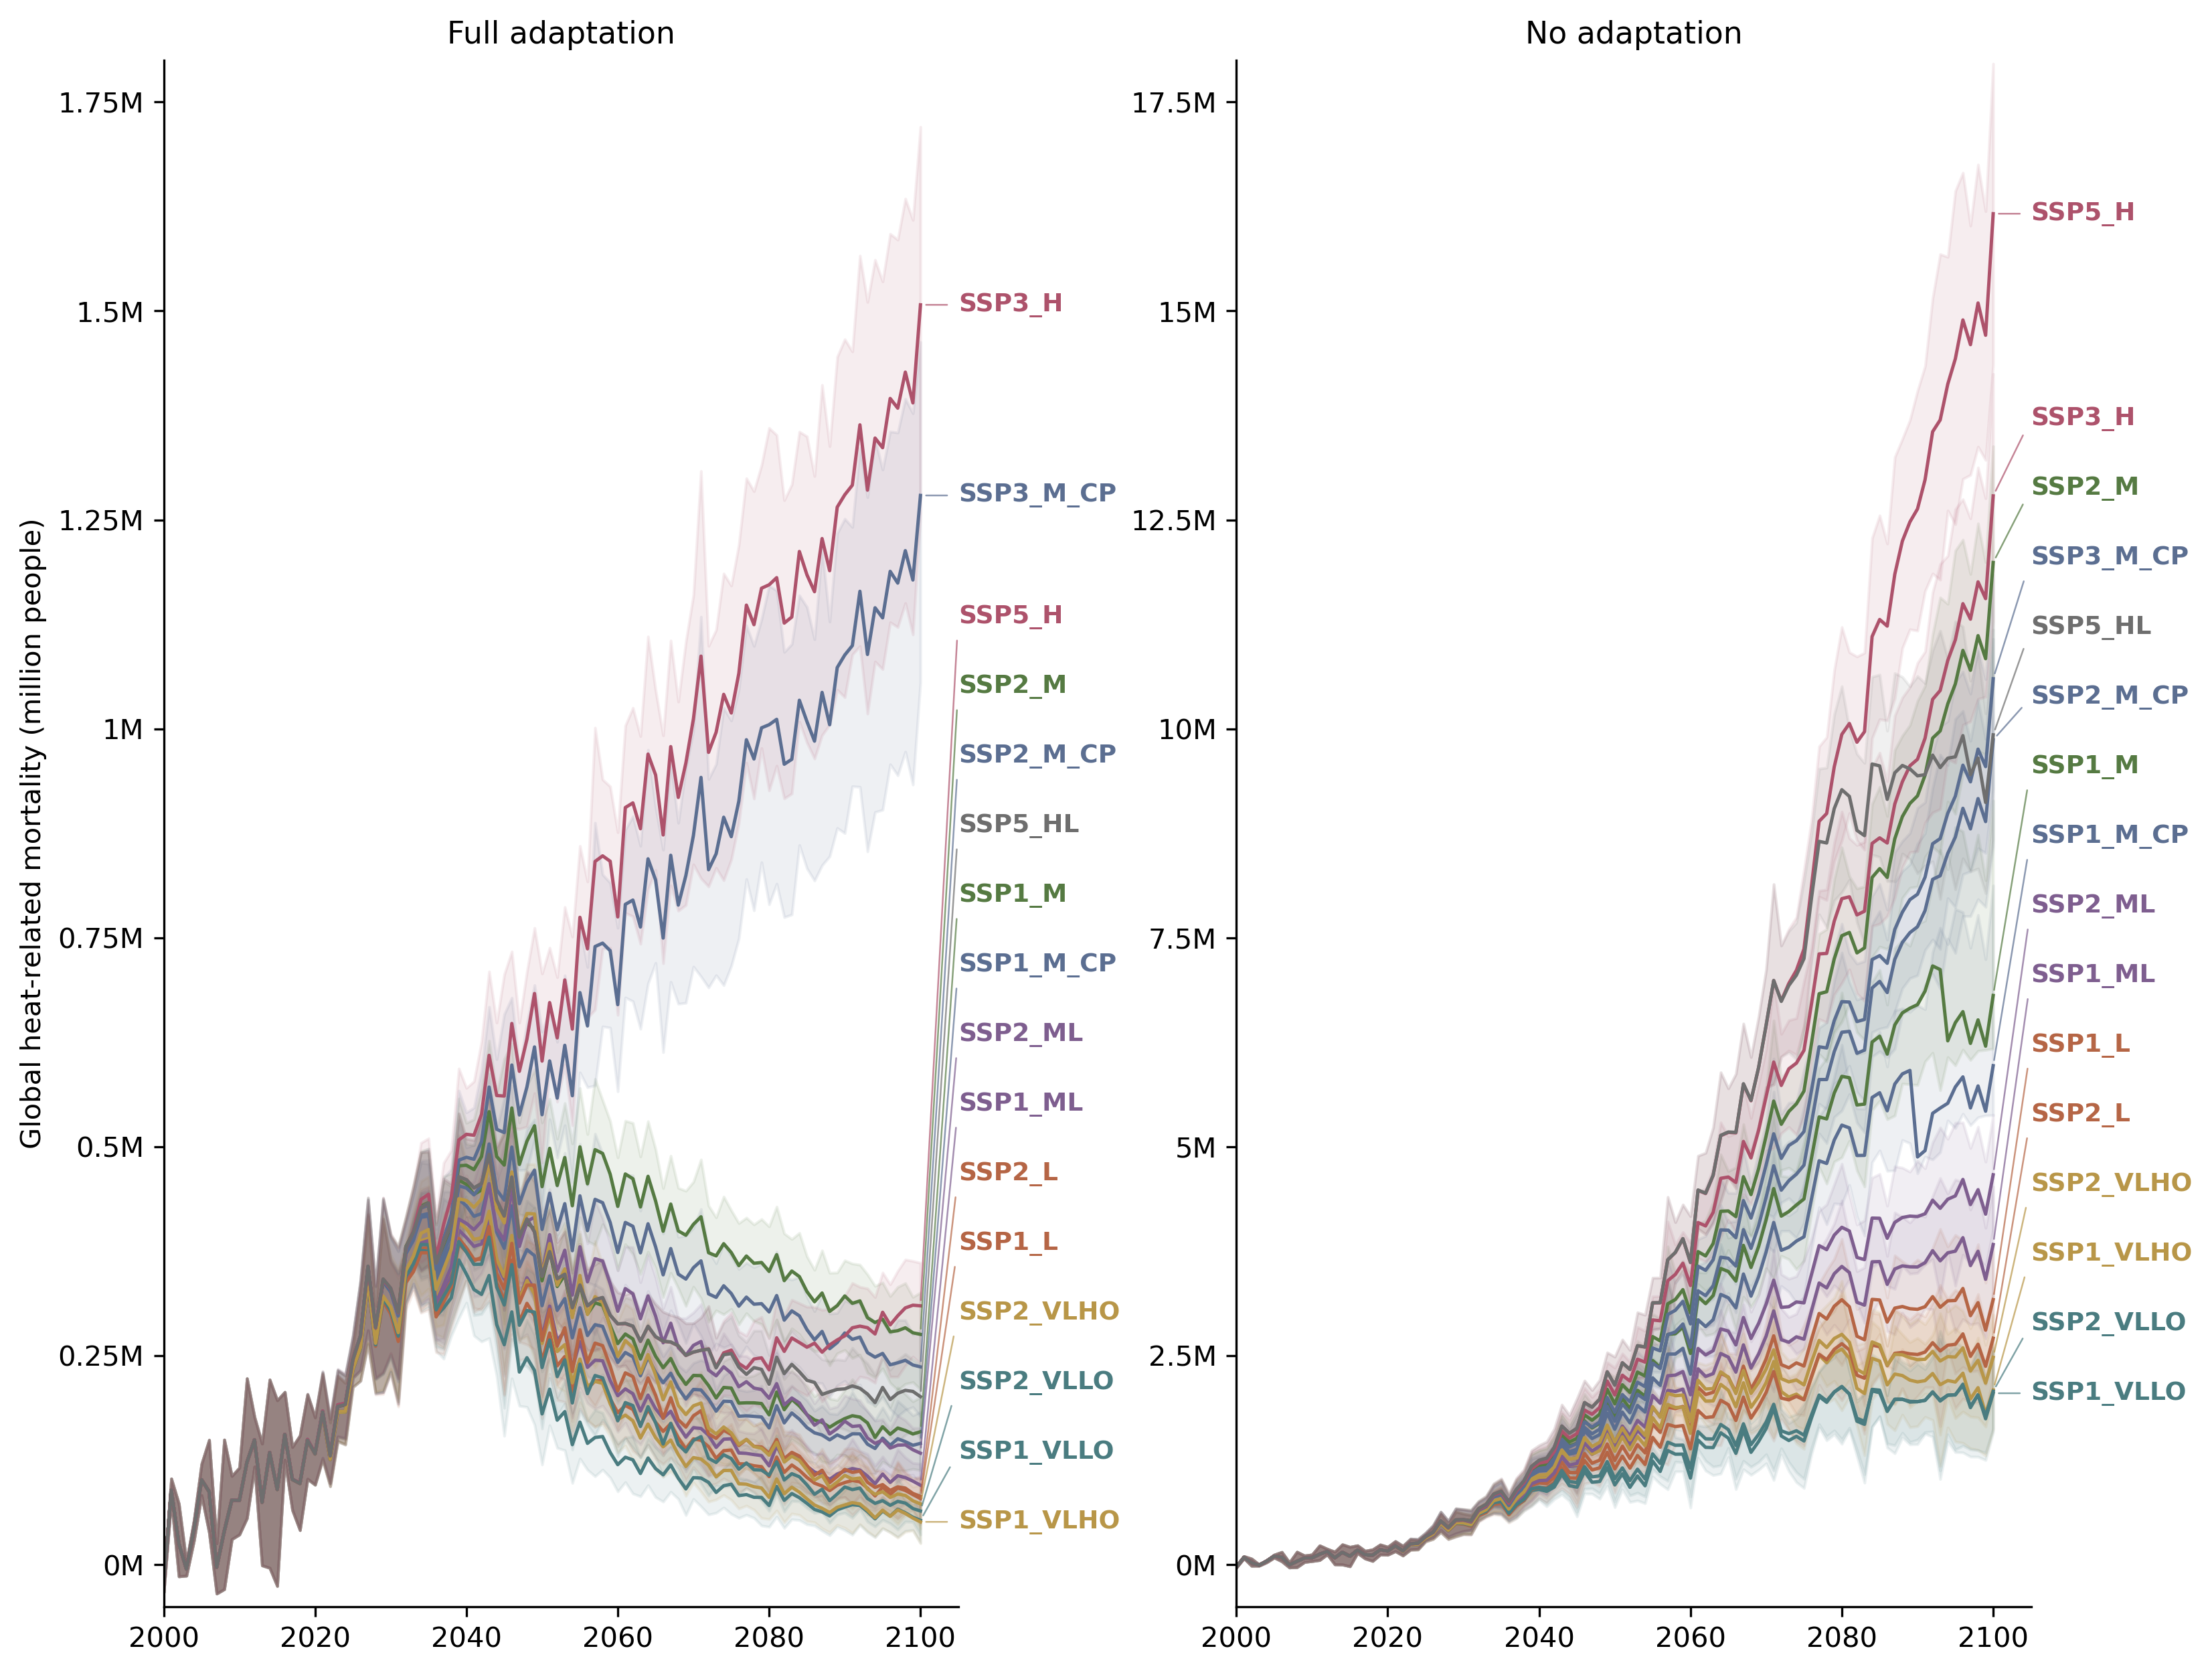

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 10), dpi=300)
ax = ax.flatten()

ax[0].set_ylim(-0.5e5, 1.8e6)
ax[1].set_ylim(-0.5e6, 18e6)

for i, adap in enumerate(["_ssp", "_NoAdap"]):
    end_points = []
    
    for j, scenario in enumerate(SCENARIOS):
        filename = f"models/Carleton2022/output/ScenarioMIP7/mortality_ScenarioMIP7_{scenario}{adap}*"
        mean, lower, upper = pltkit.LoadMortalityDraws(
            wdir, filename, region_type, region, t_type, cause, age_group, variable, years=None, range=[0.25, 0.75]
        )
        
        color = target_colors[scenario.split("_")[-1]]
        
        ax[i].plot(mean.year, mean.values, linewidth=1.2, alpha=1, c=color)
        ax[i].fill_between(mean.year, lower.values, upper.values, color=color, alpha=0.1)
        
        y_end = mean.sel(year=2100).values.item()
        end_points.append((y_end, scenario, color))

    end_points.sort(key=lambda item: item[0])
    
    ymin, ymax = ax[i].get_ylim()
    min_dist = (ymax - ymin) * 0.045
    
    y_positions = []
    last_y = ymin
    for y_val, _, _ in end_points:
        y_pos = max(y_val, last_y + min_dist)
        y_positions.append(y_pos)
        last_y = y_pos

    for (y_val, scenario, color), y_pos in zip(end_points, y_positions):
        ax[i].annotate(
            scenario,
            xy=(2100, y_val),
            xytext=(2105, y_pos),
            color=color,
            fontsize=legendsize+1,
            fontweight='bold',
            va='center',
            ha='left',
            annotation_clip=False,
            arrowprops=dict(arrowstyle='-', color=color, lw=0.6, alpha=0.7, relpos=(0.0, 0.5))
        )

    ax[i].set_xlim(2000, 2105)
    ax[i].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1e6:g}M'))
    ax[i].spines["top"].set_visible(False)
    ax[i].spines["right"].set_visible(False)

ax[0].set_ylabel("Global heat-related mortality (million people)", fontsize=labelsize)
ax[0].set_title("Full adaptation", fontsize=titlesize)
ax[1].set_title("No adaptation", fontsize=titlesize)

plt.subplots_adjust(wspace=0.35)
plt.savefig(wdir + "/figures/Paper1/Appendix/SM_Scenarios_World_All.pdf", dpi=450, bbox_inches='tight')
plt.show()

In [ ]:
"""
Age-dependent results per scenario
"""

region_type="IMAGE"
t_type = "heat"
variable="mortality"
region = "World"
years = range(2000,2101)
cause=None

scenarios = { 
  "SSP1_VLLO":"SSP1_VL", "SSP2_VLHO":"SSP1_VL", "SSP1_VLHO":"SSP1_LN",  "SSP2_VLLO":"SSP_LN",
  "SSP1_L":"SSP1_L", "SSP2_L":'SSP2_L', "SSP1_ML":"SSP1_ML", "SSP2_ML":"SSP2_ML",
  "SSP1_M":"SSP1_M", "SSP2_M":"SSP2_M", "SSP1_M_CP":"SSP1_M_CP", "SSP2_M_CP":"SSP2_M_CP",
  "SSP3_M_CP":"SSP3_M_CP", "SSP5_HL":"SSP5_HL", "SSP3_H":"SSP3_H", "SSP5_H": "SSP5_H",
}
ssps = ["SSP1", "SSP2", "SSP3", "SSP5"]
emissions_scens = {"VLLO":"VL", "VLHO":"LN", "L":"L", "ML":"ML", "M":"M", "M_CP":"M_CP", "H":"H", "HL":"HL"}

colours = ["#4A7C80", "#B89648", "#B56545", "#7E5E8F", "#557A42", "#5B6E91", "#AD526B", "#6E6E6E"]

fig, ax = plt.subplots(8,4, figsize=(12,20), dpi=450)

for i, ssp in enumerate(ssps):
  for j, em_scen in enumerate(list(emissions_scens.keys())):
    
    if f"{ssp}_{em_scen}" in scenarios:
      scenario = f"{ssp}_{em_scen}"
      filename = f"models/Carleton2022/output/ScenarioMIP7/mortality_ScenarioMIP7_{scenario}_ssp*" ## By adding the "_ssp" we ensure that only adaptation scenarios are plotted
      # filename = f"models/Carleton2022/output/ScenarioMIP7/mortality_ScenarioMIP7_{scenario}_ssp245_r1_2000-2100_LHScut_50_10*"
      
      mean={}
      for k, age_group in enumerate(["oldest", "older", "young"]):
        mean[age_group], _,_ = pltkit.LoadMortalityDraws(wdir, filename, region_type, region, t_type, cause, age_group, variable, years=None, range=[0.25,0.75])
      layers = ax[j,i].stackplot(
        mean["older"].year,
        mean["oldest"].values,
        mean["older"].values,
        mean["young"].values,
        colors=[to_rgba(colours[j], alpha=a) for a in [0.6,0.8,1]],
        clip_on=False
      )
      
      ax[j,i].set_ylim(0, 1.1e6)      
      ax[j,i].spines["top"].set_visible(False)
      ax[j,i].spines["right"].set_visible(False)
      ax[j,i].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1e6:g}M'))
      ax[j,i].tick_params(axis='both', labelsize=labelsize-1)
      
    else:
      ax[j,i].spines["top"].set_visible(False)
      ax[j,i].spines["right"].set_visible(False)
      ax[j,i].set_xticks([])
      ax[j,i].set_yticks([])

    if j==0:
      ax[j,i].set_title(f"{ssp}", fontsize=titlesize, y=1.05, weight='bold')
      
    if i==0:
      ax[j,i].set_ylabel(f"{emissions_scens[em_scen]}", fontsize=labelsize, weight='bold', rotation=0, labelpad=30)
      
fig.legend(
    handles = [
        Patch(facecolor='lightgrey', label="+65 years"),  
        Patch(facecolor='dimgrey', label="5-64 years"),
        Patch(facecolor='k', label="0-4 years")  
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.1),
    ncol=3,
    fontsize=legendsize,
    frameon=False,
    title="Age Groups",
    title_fontsize=legendsize
)
      
fig.subplots_adjust(
    left=0.08,
    right=0.95,
    bottom=0.12,
    top=0.94,
    wspace=0.3,
    hspace=0.3
) 

plt.suptitle("Adaptation Scenarios", y=0.98, weight='bold', fontsize=titlesize+1)
plt.savefig(wdir+"/figures/Paper1/Appendix/SM_Scenarios_Adap.pdf", dpi=450, bbox_inches='tight')
plt.show()

In [ ]:
"""
Age-dependent results per scenario
"""

region_type="IMAGE"
t_type = "heat"
variable="mortality"
region = "World"
years = range(2000,2101)
cause=None

scenarios = { 
  "SSP1_VLLO":"SSP1_VL", "SSP2_VLHO":"SSP1_VL", "SSP1_VLHO":"SSP1_LN",  "SSP2_VLLO":"SSP_LN",
  "SSP1_L":"SSP1_L", "SSP2_L":'SSP2_L', "SSP1_ML":"SSP1_ML", "SSP2_ML":"SSP2_ML",
  "SSP1_M":"SSP1_M", "SSP2_M":"SSP2_M", "SSP1_M_CP":"SSP1_M_CP", "SSP2_M_CP":"SSP2_M_CP",
  "SSP3_M_CP":"SSP3_M_CP", "SSP5_HL":"SSP5_HL", "SSP3_H":"SSP3_H", "SSP5_H": "SSP5_H",
}
ssps = ["SSP1", "SSP2", "SSP3", "SSP5"]
emissions_scens = {"VLLO":"VL", "VLHO":"LN", "L":"L", "ML":"ML", "M":"M", "M_CP":"M_CP", "H":"H", "HL":"HL"}

colours = ["#4A7C80", "#B89648", "#B56545", "#7E5E8F", "#557A42", "#5B6E91", "#AD526B", "#6E6E6E"]

fig, ax = plt.subplots(8,4, figsize=(12,20), dpi=450)

for i, ssp in enumerate(ssps):
  for j, em_scen in enumerate(list(emissions_scens.keys())):
    
    if f"{ssp}_{em_scen}" in scenarios:
      scenario = f"{ssp}_{em_scen}"
      filename = f"models/Carleton2022/output/ScenarioMIP7/mortality_ScenarioMIP7_{scenario}_NoAdap*" ## By adding rhe "_NoAdap" we ensure that only NO adaptation scenarios are plotted
      # filename = f"models/Carleton2022/output/ScenarioMIP7/mortality_ScenarioMIP7_{scenario}_NoAdap_ssp245_r1_NoAdap_2000-2100_LHScut_50_10*"
      
      mean={}
      for k, age_group in enumerate(["oldest", "older", "young"]):
        mean[age_group], _,_ = pltkit.LoadMortalityDraws(wdir, filename, region_type, region, t_type, cause, age_group, variable, years=None, range=[0.25,0.75])
      layers = ax[j,i].stackplot(
        mean["older"].year,
        mean["oldest"].values,
        mean["older"].values,
        mean["young"].values,
        colors=[to_rgba(colours[j], alpha=a) for a in [0.5,0.7,1]],
        clip_on=False
      )
      
      ax[j,i].set_ylim(0, 11e6)
      ax[j,i].spines["top"].set_visible(False)
      ax[j,i].spines["right"].set_visible(False)
      ax[j,i].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1e6:g}M'))
      ax[j,i].tick_params(axis='both', labelsize=labelsize-1)
      
    else:
      ax[j,i].spines["top"].set_visible(False)
      ax[j,i].spines["right"].set_visible(False)
      ax[j,i].set_xticks([])
      ax[j,i].set_yticks([])

    if j==0:
      ax[j,i].set_title(f"{ssp}", fontsize=titlesize, y=1.05, weight='bold')
      
    if i==0:
      ax[j,i].set_ylabel(f"{emissions_scens[em_scen]}", fontsize=labelsize, weight='bold', rotation=0, labelpad=30)
      
fig.legend(
    handles = [
        Patch(facecolor='lightgrey', label="+65 years"),  
        Patch(facecolor='dimgrey', label="5-64 years"),
        Patch(facecolor='k', label="0-4 years")  
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.1),
    ncol=3,
    fontsize=legendsize,
    frameon=False,
    title="Age Groups",
    title_fontsize=legendsize
)
      
fig.subplots_adjust(
    left=0.08,
    right=0.95,
    bottom=0.12,
    top=0.94,
    wspace=0.3,
    hspace=0.3
) 

plt.suptitle("No Adaptation Scenarios", y=0.98, weight='bold', fontsize=titlesize+1)
plt.savefig(wdir+"/figures/Paper1/Appendix/SM_Scenarios_NoAdap.pdf", dpi=450, bbox_inches='tight')
plt.show()

### IMAGE regional results

In [ ]:
"""
ADAPTATION SCENARIOS PER REGION
"""

region_type="IMAGE"
t_type = "heat"
variable="mortality"
age_group = "All ages"
region = None
years = range(2000,2101)
cause = None

scenarios = { # "SSP1_L", "SSP1_M", "SSP1_ML",
  "SSP1_VLHO":"SSP1_LN", "SSP1_VLLO":"SSP1_VL",
  "SSP1_L":'SSP1_L', "SSP2_ML":"SSP2_ML", "SSP2_M":"SSP2_M", #"SSP2_VLHO", "SSP2_VLLO",
  "SSP5_HL":"SSP5_HL",
  "SSP3_H":"SSP3_H", #"SSP5_H", 
}

colours = ["#4A7C80", "#B89648", "#B56545", "#7E5E8F", "#557A42", "#5B6E91", "#AD526B", "#6E6E6E"]

fig, ax = plt.subplots(7,4, figsize=(12,20), dpi=450)
ax = ax.flatten()

adap = "_ssp"

for i, region in enumerate(list(pltkit.IMAGE_REGIONS.keys())):
    for j,scenario in enumerate(list(scenarios.keys())):
        filename = f"models/Carleton2022/output/ScenarioMIP7/mortality_ScenarioMIP7_{scenario}{adap}*"    
        # filename = f"models/Carleton2022/output/ScenarioMIP7/mortality_ScenarioMIP7_{scenario}_ssp245_r1_2000-2100_LHScut_50_1*"
        mean, lower, upper = pltkit.LoadMortalityDraws(wdir, filename, region_type, region, t_type, cause, age_group, variable, years=None, range=[0.25,0.75])
        
        k = i +1 if i in [24,25] else i

        ax[k].plot(mean.year, mean.values, linewidth=1, alpha=1, c=colours[j], label=scenarios[scenario], clip_on=False)
        fill = ax[k].fill_between(mean.year, lower.values, upper.values, color=colours[j], alpha=0.1)
        fill.set_clip_on(False)
        
        ax[k].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1e3:g}k'))
        ax[k].spines["top"].set_visible(False)
        ax[k].spines["right"].set_visible(False)
        ax[k].set_title(pltkit.IMAGE_REGIONS[region][0], fontsize=titlesize-1, weight='bold', y=1.05)
        
        if i in [0]:
            ax[i].set_ylabel("Mortality \n (thousand people)", fontsize=labelsize)
            
        if i in [4,8,12,16,20,25]:
            ax[i].set_ylabel("Mortality", fontsize=labelsize)    
            
ax[24].remove()
ax[27].remove()    

handles, labels = ax[k].get_legend_handles_labels()

leg = fig.legend(
    handles, 
    labels, 
    loc='lower center', 
    bbox_to_anchor=(0.5, 0.02),
    ncol=len(scenarios), 
    fontsize=legendsize,
    title="Scenarios",
    title_fontsize=legendsize
)

for handle, text, color in zip(leg.legend_handles, leg.get_texts(), colours):
    text.set_color(color)
    handle.set_visible(False)  
    
fig.subplots_adjust(
    left=0.08,
    right=0.95,
    bottom=0.08,
    top=0.94,
    wspace=0.3,
    hspace=0.6
)
plt.savefig(wdir+"/figures/Paper1/Appendix/SM_Scenarios_Adap_IMAGE.pdf", dpi=450, bbox_inches='tight')
plt.show()

In [ ]:
"""
NO ADAPTATION SCENARIOS PER REGION
"""

region_type="IMAGE"
t_type = "heat"
variable="mortality"
age_group = "All ages"
region = None
years = range(2000,2101)
cause = None

scenarios = { # "SSP1_L", "SSP1_M", "SSP1_ML",
  "SSP1_VLHO":"SSP1_LN", "SSP1_VLLO":"SSP1_VL",
  "SSP1_L":'SSP1_L', "SSP2_ML":"SSP2_ML", "SSP2_M":"SSP2_M", #"SSP2_VLHO", "SSP2_VLLO",
  "SSP5_HL":"SSP5_HL",
  "SSP3_H":"SSP3_H", #"SSP5_H", 
}

colours = ["#4A7C80", "#B89648", "#B56545", "#7E5E8F", "#557A42", "#5B6E91", "#AD526B", "#6E6E6E"]

fig, ax = plt.subplots(7,4, figsize=(12,20), dpi=450)
ax = ax.flatten()

adap = "_NoAdap"

for i, region in enumerate(list(pltkit.IMAGE_REGIONS.keys())):
    for j,scenario in enumerate(list(scenarios.keys())):
        filename = f"models/Carleton2022/output/ScenarioMIP7/mortality_ScenarioMIP7_{scenario}{adap}*"    
        # filename = f"models/Carleton2022/output/ScenarioMIP7/mortality_ScenarioMIP7_{scenario}_ssp245_r1_2000-2100_LHScut_50_10*"
        mean, lower, upper = pltkit.LoadMortalityDraws(wdir, filename, region_type, region, t_type, cause, age_group, variable, years=None, range=[0.25,0.75])
        
        k = i +1 if i in [24,25] else i

        ax[k].plot(mean.year, mean.values, linewidth=1, alpha=1, c=colours[j], label=scenarios[scenario], clip_on=False)
        fill = ax[k].fill_between(mean.year, lower.values, upper.values, color=colours[j], alpha=0.1)
        fill.set_clip_on(False)
        
        ax[k].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1e3:g}k'))
        ax[k].spines["top"].set_visible(False)
        ax[k].spines["right"].set_visible(False)
        ax[k].set_title(pltkit.IMAGE_REGIONS[region][0], fontsize=titlesize-1, weight='bold', y=1.05)
        
        if i in [0]:
            ax[i].set_ylabel("Mortality \n (thousand people)", fontsize=labelsize)
            
        if i in [4,8,12,16,20,25]:
            ax[i].set_ylabel("Mortality", fontsize=labelsize)    
            
ax[24].remove()
ax[27].remove()    

handles, labels = ax[k].get_legend_handles_labels()

leg = fig.legend(
    handles, 
    labels, 
    loc='lower center', 
    bbox_to_anchor=(0.5, 0.02),
    ncol=len(scenarios),
    # frameon=False, 
    fontsize=legendsize,
    title="Scenarios",
    title_fontsize=legendsize
)

for handle, text, color in zip(leg.legend_handles, leg.get_texts(), colours):
    text.set_color(color)
    handle.set_visible(False)  
    
fig.subplots_adjust(
    left=0.08,
    right=0.95,
    bottom=0.08,
    top=0.94,
    wspace=0.3,
    hspace=0.6
)
# plt.suptitle("Heat-related mortality projections under ScenarioMIP7 for the regions in the IMAGE model \n Adaptation scenarios", y=0.98)
plt.savefig(wdir+"/figures/Paper1/Appendix/SM_Scenarios_NoAdap_IMAGE.pdf", dpi=450, bbox_inches='tight')
plt.show()

### Shapley-Owen

In [ ]:
"""
Missing IMAGE regions
"""

regions_covered = {"CHN":"China region", "INDIA":"India", "WEU":"Western Europe", 
           "USA":"United States", "BRA":'Brazil', "SAF":"South Africa"}
missing_regions = [region for region in list(pltkit.IMAGE_REGIONS.keys()) if region not in list(regions_covered.keys())]

predictors = ["ssp", "climate", "variability", "erf"]

dfs = {}
for region in missing_regions:
    dfs[region] = pd.read_parquet(
        wdir
        + f"models/carleton2022/output/ScenarioMIP7/Shapley/ShapleyPlot_{region}_All ages.parquet"
    )

colours = {
    "Plot_Avg_SD": "#FF000000",  # Transparent
    "Plot_Avg_SD_Surrogate": "#9cd993",
    "Plot_ssp": "#9cd993",
    "Plot_climate": "#fa9e50",
    "Plot_variability": "#226fac",
    "Plot_erf": "#c9263d",
    "Plot_Resid": "#7a5cf8",
}

fig, ax = plt.subplots(5,4, figsize=(12,16), dpi=450)
axs = ax.flatten()

for i, ax in enumerate(axs):
    
    region = missing_regions[i]
    df = dfs[region]

    df[
        ["Year", "Plot_Avg_SD", "Plot_Avg_SD_Surrogate"]
        + [f"Plot_{p}" for p in predictors]
        + ["Plot_Resid"]
    ][::5].set_index("Year").plot(
        kind="bar",
        stacked=True,
        color=colours,
        edgecolor="none",
        width=0.6,
        ax=ax,
        legend=False,
    )

    ax.plot(
        df["Average"].rolling(window=5, min_periods=1).mean()[::5].values,
        color="k", linewidth=1
    )

    ax.plot(
        df["Median"].rolling(window=5, min_periods=1).mean()[::5].values, 
        linestyle="--", color="k", linewidth=1
    )

    ax.set_title(f"{pltkit.IMAGE_REGIONS[region][0]}", fontweight="bold", fontsize=labelsize)
    ax.set_xticks(ax.get_xticks()[::4])
    ax.set_xlabel("")
    ax.tick_params(axis='both', labelsize=labelsize-2)
    ax.tick_params(axis='x', rotation=0)
    ax.spines[["top", "right"]].set_visible(False)
    
    if i in [0]:
        ax.set_ylabel("Total mortality \n (thousand people)", fontsize=labelsize)
    if i in [4, 8, 12, 16]:
        ax.set_ylabel("Total mortality", fontsize=labelsize)
            
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1000:,.1f}k'))
    
    current_ticks = ax.get_xticks()
    current_labels = [label.get_text() for label in ax.get_xticklabels()]
    ax.set_xticks(current_ticks[::2])
    ax.set_xticklabels(current_labels[::2])

handles_raw, labels_raw = axs[0].get_legend_handles_labels()
map_legend = {
    "Average": "Average",
    "Plot_ssp": "SSP",
    "Plot_climate": "Climate Change",
    "Median": "Median",
    "Plot_variability": "Climate Variability",
    "Plot_erf": "ERF uncertainty",
}
handles_filtered = []
labels_filtered = []

for h, l in zip(handles_raw, labels_raw):
    if l in map_legend:
        handles_filtered.append(h)
        labels_filtered.append(map_legend[l])
        
fig.legend(
    handles=handles_filtered,
    labels=labels_filtered,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=4,
    frameon=False,
    fontsize=legendsize,
)

plt.tight_layout()
plt.savefig(wdir+"/figures/Paper1/Appendix/SM_ShapleyOwen_IMAGE.pdf", dpi=450, bbox_inches='tight')
plt.show()